<div style="background: linear-gradient(135deg, #4a7c59, #7ba05b); 
            border-radius: 10px; 
            padding: 25px; 
            box-shadow: 0 4px 20px rgba(0,0,0,0.15);
            margin-bottom: 30px">
  <h1 style="font-family: 'Helvetica Neue', Arial, sans-serif; 
             font-size: 36px; 
             font-weight: 700; 
             color: white; 
             text-align: center;
             margin: 0;
             text-shadow: 1px 1px 3px rgba(0,0,0,0.2)">
    Fertilizer Classification Challenge
  </h1>
  <h2 style="font-family: 'Helvetica Neue', Arial, sans-serif; 
             font-size: 22px; 
             font-weight: 300; 
             color: rgba(255,255,255,0.9); 
             text-align: center;
             margin-top: 10px">
    Baseline Model with H2O XGBoost
  </h2>
</div>

<div style="font-family: 'Helvetica Neue', Arial, sans-serif; 
            font-size: 16px; 
            line-height: 1.6; 
            color: #333;
            background-color: #fff;
            padding: 25px;
            border-radius: 8px;
            border-left: 4px solid #5c9bd1">
  <p style="margin-top: 0">
    This notebook presents my approach to the <strong>Playground Series Season 5 Episode 6</strong> 
    fertilizer classification challenge. The task involves predicting the appropriate fertilizer type 
    from three distinct classes based on various soil properties and environmental conditions that 
    influence agricultural decision-making.
  </p>
  
  <h3 style="color: #2e6c80; margin-top: 25px; margin-bottom: 15px">What is H2O?</h3>
  <p>
    H2O is an open-source machine learning platform that is used for automating repetitive tasks that are involved in machine learning . 
    It's basically a Java-based framework that provides really fast implementations of popular algorithms 
    like XGBoost, Random Forest, and GLM. What I love about H2O is that it handles the heavy lifting of 
    distributed computing - you can run it on a single machine or scale it across clusters without 
    changing your code. The platform automatically handles memory management and parallel processing, 
    which means I can focus on the actual modeling instead of worrying about technical infrastructure.
  </p>
  
  <h3 style="color: #2e6c80; margin-top: 25px; margin-bottom: 15px">My Approach</h3>
    <p>
    I'm using XGBoost as my core algorithm because it consistently performs well on structured data 
    with mixed feature types. My approach combines the competition training data with an external 
    fertilizer dataset to give the model more examples of soil-fertilizer relationships. The model 
    is optimized for logarithmic loss, which is perfect for multi-class problems since it heavily 
    penalizes confident wrong predictions - crucial when wrong fertilizer recommendations could 
    impact actual crop yields.
  </p>
  
  <p>
    The evaluation metric for this competition is MAP@3 (Mean Average Precision at 3), which measures 
    how well the model ranks the correct fertilizer among its top 3 predictions. This makes sense 
    from an agricultural perspective since farmers often have multiple viable fertilizer options. 
    I've implemented early stopping based on validation logloss to prevent overfitting, and I'm 
    using a 90/10 train-validation split with cross-validation predictions saved for potential 
    ensemble methods. The entire pipeline leverages GPU acceleration for faster experimentation 
    with hyperparameters and model iterations.
  </p>
  
  
  <div style="margin-top: 25px; padding: 15px; background-color: #e3eeff; border-radius: 6px">
    <p style="margin: 0">
      <strong>A Quick Note:</strong> This whole approach has been a bit of a learning experience for me. 
      Working with agricultural data is different from typical ML problems - there's real-world domain 
      knowledge that matters, and the stakes feel higher because we're talking about actual crop 
      decisions. I've tried to balance technical rigor with practical insights, and I hope this 
      notebook gives you some useful ideas for your own approach to the problem.
    </p>
  </div>
</div>

In [1]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from h2o.estimators import H2OXGBoostEstimator
import h2o
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
warnings.filterwarnings("ignore")

h2o.init()


Checking whether there is an H2O instance running at http://localhost:54321..... not found.
Attempting to start a local H2O server...
  Java Version: openjdk version "11.0.26" 2025-01-21; OpenJDK Runtime Environment (build 11.0.26+4-post-Ubuntu-1ubuntu122.04); OpenJDK 64-Bit Server VM (build 11.0.26+4-post-Ubuntu-1ubuntu122.04, mixed mode, sharing)
  Starting server from /usr/local/lib/python3.11/dist-packages/h2o/backend/bin/h2o.jar
  Ice root: /tmp/tmpde3pch71
  JVM stdout: /tmp/tmpde3pch71/h2o_unknownUser_started_from_python.out
  JVM stderr: /tmp/tmpde3pch71/h2o_unknownUser_started_from_python.err
  Server is running at http://127.0.0.1:54321
Connecting to H2O server at http://127.0.0.1:54321 ... successful.
Please download and install the latest version from: https://h2o-release.s3.amazonaws.com/h2o/latest_stable.html


H2O_cluster_uptime:,02 secs
H2O_cluster_timezone:,Etc/UTC
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.7
H2O_cluster_version_age:,3 months and 11 days
H2O_cluster_name:,H2O_from_python_unknownUser_p5oof7
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,7.250 Gb
H2O_cluster_total_cores:,4
H2O_cluster_allowed_cores:,4
H2O_cluster_status:,"locked, healthy"


<div style="background: linear-gradient(135deg, #4a7c59, #7ba05b); 
            border-radius: 10px; 
            padding: 20px; 
            box-shadow: 0 4px 15px rgba(0,0,0,0.1);
            margin: 20px 0">
  <h2 style="font-family: 'Helvetica Neue', Arial, sans-serif; 
             font-size: 28px; 
             font-weight: 600; 
             color: white; 
             text-align: center;
             margin: 0;
             text-shadow: 1px 1px 2px rgba(0,0,0,0.2)">
    📊 Data Loading & Preparation
  </h2>
</div>
<div style="font-family: 'Helvetica Neue', Arial, sans-serif; 
            font-size: 15px; 
            line-height: 1.5; 
            color: #333;
            background-color: #fff;
            padding: 20px;
            border-radius: 8px;
            border-left: 4px solid #7ba05b;
            margin-bottom: 15px">
  <p style="margin: 0">
   The competition datasets are being used alongside an external fertilizer dataset to increase the number of training examples. After merging the datasets, duplicate entries will be removed to maintain data quality and reduce the risk of overfitting.
  </p>
</div>

In [2]:
# Load datasets
train = pd.read_csv("/kaggle/input/playground-series-s5e6/train.csv", index_col="id")
test = pd.read_csv("/kaggle/input/playground-series-s5e6/test.csv", index_col="id")
external = pd.read_csv("/kaggle/input/fertilizer-prediction/Fertilizer Prediction.csv")

# Combine datasets
overall_train = pd.concat([train, external], ignore_index=True)
overall_train = overall_train.drop_duplicates().reset_index(drop=True)
overall_train.head(5)

,Temparature,Humidity,Moisture,Soil Type,Crop Type,Nitrogen,Potassium,Phosphorous,Fertilizer Name
0,37,70,36,Clayey,Sugarcane,36,4,5,28-28
1,27,69,65,Sandy,Millets,30,6,18,28-28
2,29,63,32,Sandy,Millets,24,12,16,17-17-17
3,35,62,54,Sandy,Barley,39,12,4,10-26-26
4,35,58,43,Red,Paddy,37,2,16,DAP


<div style="background: linear-gradient(135deg, #4a7c59, #7ba05b); 
            border-radius: 10px; 
            padding: 20px; 
            box-shadow: 0 4px 15px rgba(0,0,0,0.1);
            margin: 20px 0">
  <h2 style="font-family: 'Helvetica Neue', Arial, sans-serif; 
             font-size: 28px; 
             font-weight: 600; 
             color: white; 
             text-align: center;
             margin: 0;
             text-shadow: 1px 1px 2px rgba(0,0,0,0.2)">
    🔄 H2O Data Conversion
  </h2>
</div>
<div style="font-family: 'Helvetica Neue', Arial, sans-serif; 
            font-size: 15px; 
            line-height: 1.5; 
            color: #333;
            background-color: #fff;
            padding: 20px;
            border-radius: 8px;
            border-left: 4px solid #9333ea;
            margin-bottom: 15px">
  <p style="margin: 0">
   The pandas DataFrames are being converted into H2O’s native format to enable compatibility with H2O’s distributed processing capabilities. The target variable is encoded, and categorical features are appropriately flagged to ensure proper handling by H2O’s algorithms.
  </p>
</div>

In [3]:
# Convert to H2O frames
trainH2o = h2o.H2OFrame(overall_train)
testH2o = h2o.H2OFrame(test)

# Encode target variable
target_encoder = LabelEncoder()
y_encoded = target_encoder.fit_transform(overall_train['Fertilizer Name']).tolist()
targetH2o = h2o.H2OFrame(y_encoded)
trainH2o['Fertilizer Name'] = targetH2o
trainH2o['Fertilizer Name'] = trainH2o['Fertilizer Name'].asfactor()

# Handle categorical features
categorical_features = test.select_dtypes(include="object").columns.tolist()
for col in categorical_features:
    trainH2o[col] = trainH2o[col].asfactor()
    testH2o[col] = testH2o[col].asfactor()

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%



<div style="background: linear-gradient(135deg, #4a7c59, #7ba05b); 
            border-radius: 10px; 
            padding: 20px; 
            box-shadow: 0 4px 15px rgba(0,0,0,0.1);
            margin: 20px 0">
  <h2 style="font-family: 'Helvetica Neue', Arial, sans-serif; 
             font-size: 28px; 
             font-weight: 600; 
             color: white; 
             text-align: center;
             margin: 0;
             text-shadow: 1px 1px 2px rgba(0,0,0,0.2)">
    ⚙️ Model Configuration
  </h2>
</div>
<div style="font-family: 'Helvetica Neue', Arial, sans-serif; 
            font-size: 15px; 
            line-height: 1.5; 
            color: #333;
            background-color: #fff;
            padding: 20px;
            border-radius: 8px;
            border-left: 4px solid #f97316;
            margin-bottom: 15px">
  <p style="margin: 0">
   The XGBoost model is configured with parameters selected for this task, including GPU acceleration to improve training speed. A 90/10 train-validation split is used, and early stopping is enabled to help mitigate overfitting. Here I'm setting up the XGBoost model with parameters I've tuned for this specific problem, including GPU acceleration for faster training. I'm using a 90/10 train-validation split and enabling early stopping to prevent overfitting .
  </p>
</div>

In [4]:
# Define model parameters
x_columns = [col for col in overall_train.columns if col != 'Fertilizer Name']
y_column = "Fertilizer Name"

# Split data
train_split, valid_split = trainH2o.split_frame(ratios=[0.9], seed=42)

# Initialize model
xgb_model = H2OXGBoostEstimator(
   stopping_rounds=20,
    stopping_metric="logloss",
    stopping_tolerance=0.001,
    score_tree_interval=10,
    seed=42,
    keep_cross_validation_predictions=True,
    booster='gbtree',
    ntrees=100,                          
    learn_rate=0.1,  
    gpu_id = 0, 
    max_depth=15,
    min_rows=10,                            
    sample_rate=0.8276149323901826,        
    col_sample_rate=0.2587327850345624,    
    distribution='multinomial',           
    categorical_encoding='auto',           
    quiet_mode=True,
    backend='gpu',
    tree_method="hist",   
    reg_lambda = 0.05656209749983576,  
    reg_alpha = 5.620898657099113

    
)


<div style="background: linear-gradient(135deg, #4a7c59, #7ba05b); 
            border-radius: 10px; 
            padding: 20px; 
            box-shadow: 0 4px 15px rgba(0,0,0,0.1);
            margin: 20px 0">
  <h2 style="font-family: 'Helvetica Neue', Arial, sans-serif; 
             font-size: 28px; 
             font-weight: 600; 
             color: white; 
             text-align: center;
             margin: 0;
             text-shadow: 1px 1px 2px rgba(0,0,0,0.2)">
    🚀 Model Training
  </h2>
</div>
<div style="font-family: 'Helvetica Neue', Arial, sans-serif; 
            font-size: 15px; 
            line-height: 1.5; 
            color: #333;
            background-color: #fff;
            padding: 20px;
            border-radius: 8px;
            border-left: 4px solid #10b981;
            margin-bottom: 15px">
  <p style="margin: 0">
    The model is trained using the configured XGBoost setup with GPU acceleration. Early stopping is managed automatically based on validation performance, eliminating the need for manual monitoring during training.
  </p>
</div>

In [5]:
# Train model
xgb_model.train(
    x=x_columns,
    y=y_column,
    training_frame=train_split,
    validation_frame=valid_split
)



xgboost Model Build progress: |██████████████████████████████████████████████████| (done) 100%


Model Details
=============
H2OXGBoostEstimator : XGBoost
Model Key: XGBoost_model_python_1752048979964_1


Model Summary: 
    number_of_trees
--  -----------------
    100

ModelMetricsMultinomial: xgboost
** Reported on train data. **

MSE: 0.6947181027648109
RMSE: 0.8334975121527424
LogLoss: 1.8095798426655507
Mean Per-Class Error: 0.6425348871002292
AUC table was not computed: it is either disabled (model parameter 'auc_type' was set to AUTO or NONE) or the domain size exceeds the limit (maximum is 50 domains).
AUCPR table was not computed: it is either disabled (model parameter 'auc_type' was set to AUTO or NONE) or the domain size exceeds the limit (maximum is 50 domains).

Confusion Matrix: Row labels: Actual class; Column labels: Predicted class
0       1       2       3       4       5      6      Error     Rate
------  ------  ------  ------  ------  -----  -----  --------  -----------------
49873   16110   14355   11884   12842   6308   4169   0.568352  65,668 / 115,541
14937   51428   14434   11860   12836   6175   4221   0.556238  64,463 / 115,891
14861   16203   46872   11994   13321   6331   4301   0.58842   67,011 / 113,883
15293   16231   14747   41865   13364   6567   4355   0.627608  70,557 / 112,422
15005   15862   14564   12231   44816   6379   4130   0.603353  68,171 / 112,987
14421   15241   13677   12227   13218   24945  4473   0.745983  73,257 / 98,202
14820   15760   14308   12201   13779   6633   18441  0.80779   77,501 / 95,942
139210  146835  132957  114262  124176  63338  44090  0.636225  486,628 / 764,868

Top-7 Hit Ratios: 
k    hit_ratio
---  -----------
1    0.363775
2    0.569962
3    0.713277
4    0.819347
5    0.899426
6    0.960768
7    1

ModelMetricsMultinomial: xgboost
** Reported on validation data. **

MSE: 0.7223918984301874
RMSE: 0.8499364084625316
LogLoss: 1.9147228565542984
Mean Per-Class Error: 0.8012159677795536
AUC table was not computed: it is either disabled (model parameter 'auc_type' was set to AUTO or NONE) or the domain size exceeds the limit (maximum is 50 domains).
AUCPR table was not computed: it is either disabled (model parameter 'auc_type' was set to AUTO or NONE) or the domain size exceeds the limit (maximum is 50 domains).

Confusion Matrix: Row labels: Actual class; Column labels: Predicted class
0      1      2      3      4      5     6     Error     Rate
-----  -----  -----  -----  -----  ----  ----  --------  ---------------
3066   2381   2041   1759   1914   935   628   0.759038  9,658 / 12,724
2215   3423   2201   1733   1903   896   666   0.73744   9,614 / 13,037
2102   2339   3207   1749   1897   841   607   0.748313  9,535 / 12,742
2266   2202   2084   2481   2027   976   612   0.803843  10,167 / 12,648
2150   2281   1969   1760   2664   914   665   0.785213  9,739 / 12,403
1915   1886   1700   1559   1711   1462  645   0.8656    9,416 / 10,878
1897   1952   1746   1529   1721   882   973   0.909065  9,727 / 10,700
15611  16464  14948  12570  13837  6906  4796  0.797068  67,856 / 85,132

Top-7 Hit Ratios: 
k    hit_ratio
---  -----------
1    0.202932
2    0.372234
3    0.524104
4    0.663898
5    0.789539
6    0.90281
7    1

Scoring History: 
    timestamp            duration          number_of_trees    training_rmse    training_logloss    training_classification_error    training_auc    training_pr_auc    validation_rmse    validation_logloss    validation_classification_error    validation_auc    validation_pr_auc
--  -------------------  ----------------  -----------------  ---------------  ------------------  -------------------------------  --------------  -----------------  -----------------  --------------------  ---------------------------------  ----------------  -------------------
    2025-07-09 08:16:41  0.048 sec         0                  0.857143         1.94591             0.852279                         nan             nan                0.857143           1.94591               0.854309                           nan               nan


<div style="background:linear-gradient(135deg, #4a7c59, #7ba05b); 
            border-radius: 10px; 
            padding: 20px; 
            box-shadow: 0 4px 15px rgba(0,0,0,0.1);
            margin: 20px 0">
  <h2 style="font-family: 'Helvetica Neue', Arial, sans-serif; 
             font-size: 28px; 
             font-weight: 600; 
             color: white; 
             text-align: center;
             margin: 0;
             text-shadow: 1px 1px 2px rgba(0,0,0,0.2)">
    📊 Model Performance Analysis
  </h2>
</div>
<div style="font-family: 'Helvetica Neue', Arial, sans-serif; 
            font-size: 15px; 
            line-height: 1.5; 
            color: #333;
            background-color: #fff;
            padding: 20px;
            border-radius: 8px;
            border-left: 4px solid #a855f7;
            margin-bottom: 15px">
  <p style="margin: 0">
   Model performance is evaluated by reviewing validation metrics and plotting the training history. The logloss curves are examined to assess potential overfitting and to verify that early stopping was triggered appropriately.
  </p>
</div>

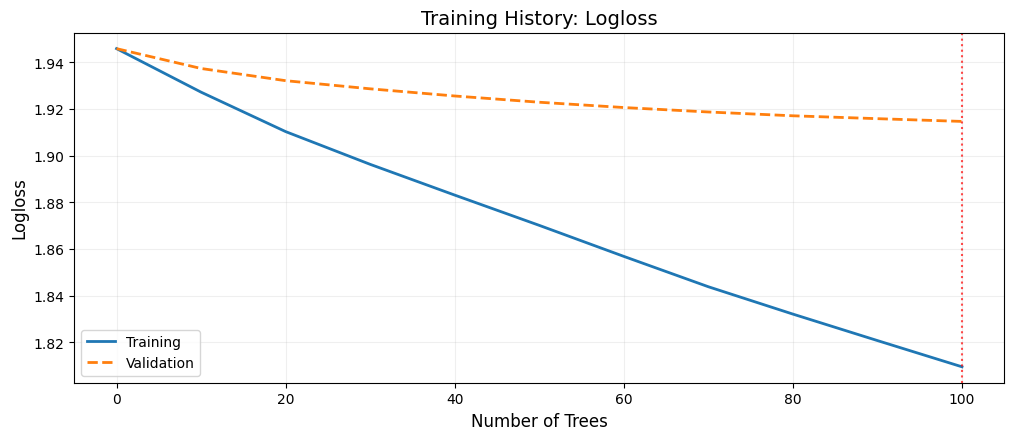

In [6]:
# Get model performance
perf = xgb_model.model_performance(valid_split)

# Plot training history 
scoring_history = xgb_model.scoring_history()
plt.figure(figsize=(12, 10))

# Logloss plot
plt.subplot(2, 1, 1)
plt.plot(scoring_history['number_of_trees'], scoring_history['training_logloss'], 
         label='Training', linewidth=2)
plt.plot(scoring_history['number_of_trees'], scoring_history['validation_logloss'], 
         label='Validation', linewidth=2, linestyle='--')
plt.title('Training History: Logloss', fontsize=14)
plt.xlabel('Number of Trees', fontsize=12)
plt.ylabel('Logloss', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.2)
plt.axvline(x=scoring_history['number_of_trees'].iloc[-1], 
            color='r', linestyle=':', alpha=0.7)

<div style="background:linear-gradient(135deg, #4a7c59, #7ba05b); 
            border-radius: 10px; 
            padding: 20px; 
            box-shadow: 0 4px 15px rgba(0,0,0,0.1);
            margin: 20px 0">
  <h2 style="font-family: 'Helvetica Neue', Arial, sans-serif; 
             font-size: 28px; 
             font-weight: 600; 
             color: white; 
             text-align: center;
             margin: 0;
             text-shadow: 1px 1px 2px rgba(0,0,0,0.2)">
    🎯 MAP@3 Evaluation
  </h2>
</div>
<div style="font-family: 'Helvetica Neue', Arial, sans-serif; 
            font-size: 15px; 
            line-height: 1.5; 
            color: #333;
            background-color: #fff;
            padding: 20px;
            border-radius: 8px;
            border-left: 4px solid #06b6d4;
            margin-bottom: 15px">
  <p style="margin: 0">
Since MAP@3 is the primary evaluation metric for this competition, a custom function is implemented to compute it accurately. This metric evaluates how effectively the model ranks the correct fertilizer within its top three predictions, offering a more relevant assessment than overall accuracy for this task and its being used on validation data to test the models perfomance  </p>
</div>

In [7]:
 #MAP@3 Evaluation Function
def map_at_3(y_true, y_pred_proba, k=3):
    top_k = np.argsort(-y_pred_proba, axis=1)[:, :k]
    ranks = np.argwhere(top_k == y_true.reshape(-1, 1))[:, 1] + 1
    map_score = np.sum(1 / ranks) / len(y_true)
    return map_score

# Calculate MAP@3
print("\nEvaluating model performance...")
val_preds = xgb_model.predict(valid_split)
val_preds_df = val_preds.as_data_frame()
n_classes = len(target_encoder.classes_)
prob_cols = [f"p{i}" for i in range(n_classes)]
y_pred_proba = val_preds_df[prob_cols].values
y_true = valid_split[y_column].as_data_frame().values.flatten()

validation_map3 = map_at_3(y_true, y_pred_proba)
logloss = xgb_model.logloss(valid=True)

print(f"Validation MAP@3: {validation_map3:.6f}")
print(f"Validation Logloss: {logloss:.5f}")


Evaluating model performance...
xgboost prediction progress: |███████████████████████████████████████████████████| (done) 100%
Validation MAP@3: 0.338206
Validation Logloss: 1.91472


<div style="background: linear-gradient(135deg, #4a7c59, #7ba05b); 
            border-radius: 10px; 
            padding: 20px; 
            box-shadow: 0 4px 15px rgba(0,0,0,0.1);
            margin: 20px 0">
  <h2 style="font-family: 'Helvetica Neue', Arial, sans-serif; 
             font-size: 28px; 
             font-weight: 600; 
             color: white; 
             text-align: center;
             margin: 0;
             text-shadow: 1px 1px 2px rgba(0,0,0,0.2)">
    📝 Submission Generation
  </h2>
</div>
<div style="font-family: 'Helvetica Neue', Arial, sans-serif; 
            font-size: 15px; 
            line-height: 1.5; 
            color: #333;
            background-color: #fff;
            padding: 20px;
            border-radius: 8px;
            border-left: 4px solid #ec4899;
            margin-bottom: 15px">
  <p style="margin: 0">
    The final step involves generating predictions on the test set and formatting them to meet the competition submission requirements. For each sample, the top three predicted fertilizer types are extracted and mapped back to their original label names for submission
  </p>
</div>

In [8]:
 #Generate predictions
print("\nGenerating test predictions...")
test_preds = xgb_model.predict(testH2o)
test_preds_df = test_preds.as_data_frame()

# Prepare submission
print("Creating submission file...")
top3 = test_preds_df[prob_cols].apply(
    lambda row: row.nlargest(3).index.tolist(), 
    axis=1
)

label_map = {i: label for i, label in enumerate(target_encoder.classes_)}
top3_labels = top3.apply(lambda x: [label_map[int(col.split('p')[1])] for col in x])

submission = pd.DataFrame({
    "id": test.index,
    "Fertilizer Name": top3_labels.apply(lambda x: " ".join(x))
})

# Display submission preview
print("\nSubmission preview:")
print(submission.head())

# Save results
submission.to_csv("submission.csv", index=False)
print("\nSubmission saved successfully")


Generating test predictions...
xgboost prediction progress: |███████████████████████████████████████████████████| (done) 100%
Creating submission file...

Submission preview:
       id          Fertilizer Name
0  750000       DAP 28-28 17-17-17
1  750001  17-17-17 10-26-26 20-20
2  750002     14-35-14 28-28 20-20
3  750003    14-35-14 17-17-17 DAP
4  750004      20-20 10-26-26 Urea

Submission saved successfully


<div style="background: linear-gradient(135deg, #f59e0b, #fbbf24, #f59e0b); 
            border-radius: 15px; 
            padding: 40px; 
            box-shadow: 0 8px 25px rgba(245, 158, 11, 0.3);
            margin: 30px 0;
            text-align: center;
            border: 3px solid #fbbf24">
  <div style="font-size: 80px; margin-bottom: 20px; line-height: 1">
    👍✨🚀
  </div>
  <h1 style="font-family: 'Helvetica Neue', Arial, sans-serif; 
             font-size: 42px; 
             font-weight: 800; 
             color: #92400e; 
             margin: 20px 0;
             text-shadow: 2px 2px 4px rgba(0,0,0,0.1)">
    Found This Helpful?
  </h1>
  <h2 style="font-family: 'Helvetica Neue', Arial, sans-serif; 
             font-size: 32px; 
             font-weight: 600; 
             color: #b45309; 
             margin: 15px 0;
             line-height: 1.3">
    🌟 Please Consider Upvoting! 🌟
  </h2>
  <p style="font-family: 'Helvetica Neue', Arial, sans-serif;
            font-size: 20px;
            font-weight: 500;
            color: #92400e;
            margin: 25px 0;
            line-height: 1.4">
    Your upvote helps others discover this notebook and motivates me to create more detailed tutorials! 
    It takes just one click but means the world to content creators like me.
  </p>
  <div style="font-size: 60px; margin: 25px 0; line-height: 1">
    🙏💛📈
  </div>
  <h3 style="font-family: 'Helvetica Neue', Arial, sans-serif; 
             font-size: 28px; 
             font-weight: 700; 
             color: #b45309; 
             margin: 20px 0">
    Thank You for Your Support! 🎉
  </h3>
</div>